# Lab 5: Data Visualization using Matplotlib (Air Quality Index)
**Aim:** Visualize AQI trends, pollutant levels, bar charts, box plots, scatter plots, and highlight peak values.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression

# 1. Generate AQI Dataset
X, _ = make_regression(n_samples=30, n_features=3, random_state=42)
df = pd.DataFrame(X, columns=['PM25_raw', 'PM10_raw', 'CO_raw'])
df['Date'] = pd.date_range('2025-01-01', periods=30)
df['PM25'] = ((df['PM25_raw'] - df['PM25_raw'].min()) / (df['PM25_raw'].max() - df['PM25_raw'].min())) * 150 + 20
df['PM10'] = ((df['PM10_raw'] - df['PM10_raw'].min()) / (df['PM10_raw'].max() - df['PM10_raw'].min())) * 200 + 30
df['CO']   = ((df['CO_raw'] - df['CO_raw'].min()) / (df['CO_raw'].max() - df['CO_raw'].min())) * 10 + 1
df['AQI']  = (0.45 * df['PM25'] + 0.35 * df['PM10'] + 5 * df['CO']).round(2)
df = df[['Date', 'PM25', 'PM10', 'CO', 'AQI']]
df.head()

,Date,PM25,PM10,CO,AQI
0,2025-01-01,127.559080,111.010927,8.789638,140.20
1,2025-01-02,61.171827,107.866309,5.392011,92.24
2,2025-01-03,170.000000,69.711970,7.117339,136.49
3,2025-01-04,106.065419,225.951390,5.566368,154.64
4,2025-01-05,70.468070,39.980163,8.318296,87.30


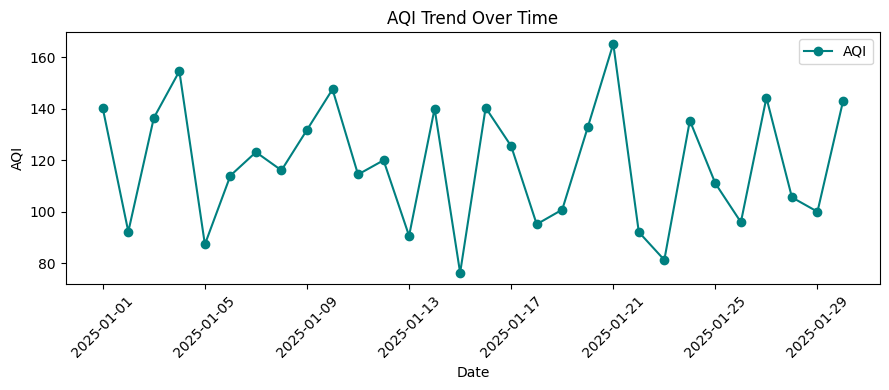

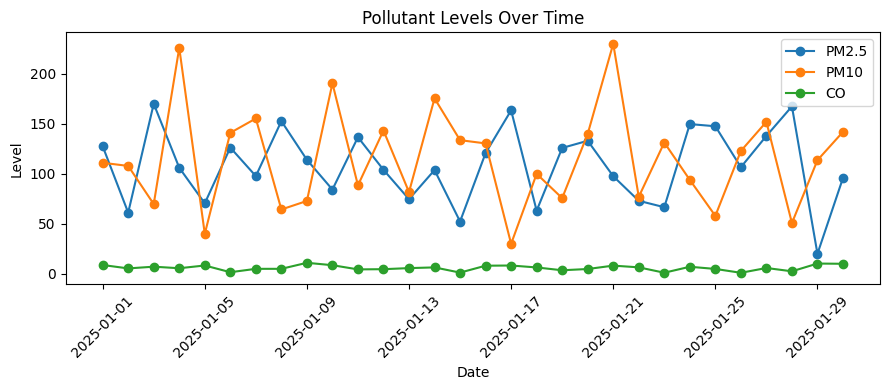

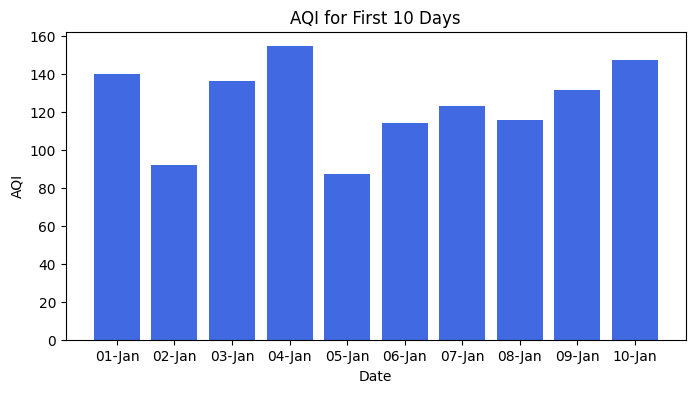

In [2]:
# 2. Line Plots & Bar Plot
plt.figure(figsize=(9, 4))
plt.plot(df['Date'], df['AQI'], marker='o', label='AQI', color='teal')
plt.title('AQI Trend Over Time')
plt.xlabel('Date'); plt.ylabel('AQI')
plt.xticks(rotation=45); plt.legend(); plt.tight_layout(); plt.show()

plt.figure(figsize=(9, 4))
plt.plot(df['Date'], df['PM25'], label='PM2.5', marker='o')
plt.plot(df['Date'], df['PM10'], label='PM10', marker='o')
plt.plot(df['Date'], df['CO'], label='CO', marker='o')
plt.title('Pollutant Levels Over Time')
plt.xlabel('Date'); plt.ylabel('Level')
plt.xticks(rotation=45); plt.legend(); plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 4))
plt.bar(df['Date'].head(10).dt.strftime('%d-%b'), df['AQI'].head(10), color='royalblue')
plt.title('AQI for First 10 Days')
plt.xlabel('Date'); plt.ylabel('AQI')
plt.show()

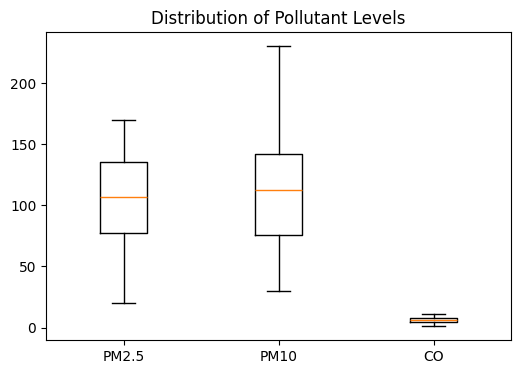

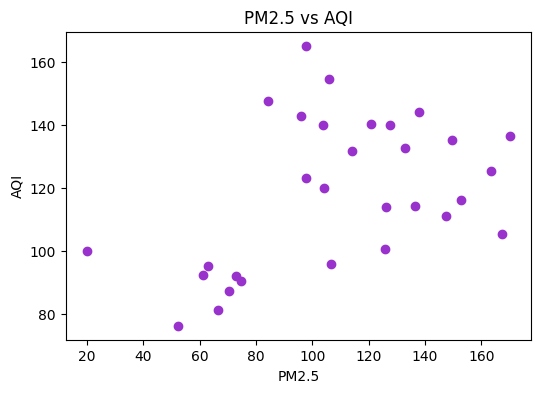

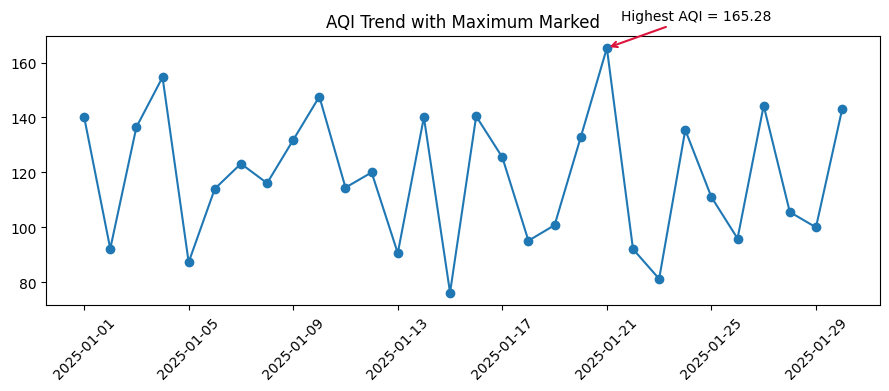

In [3]:
# 3. Box Plot, Scatter Plot & Annotation
plt.figure(figsize=(6, 4))
plt.boxplot([df['PM25'], df['PM10'], df['CO']], tick_labels=['PM2.5', 'PM10', 'CO'])
plt.title('Distribution of Pollutant Levels')
plt.show()

plt.figure(figsize=(6, 4))
plt.scatter(df['PM25'], df['AQI'], color='darkorchid')
plt.title('PM2.5 vs AQI')
plt.xlabel('PM2.5'); plt.ylabel('AQI')
plt.show()

# Annotate Highest AQI
highest = df.loc[df['AQI'].idxmax()]
plt.figure(figsize=(9, 4))
plt.plot(df['Date'], df['AQI'], marker='o')
plt.annotate(f"Highest AQI = {highest['AQI']}",
             xy=(highest['Date'], highest['AQI']),
             xytext=(10, 20), textcoords='offset points',
             arrowprops=dict(arrowstyle='->', color='crimson', lw=1.5))
plt.title('AQI Trend with Maximum Marked')
plt.xticks(rotation=45); plt.tight_layout(); plt.show()